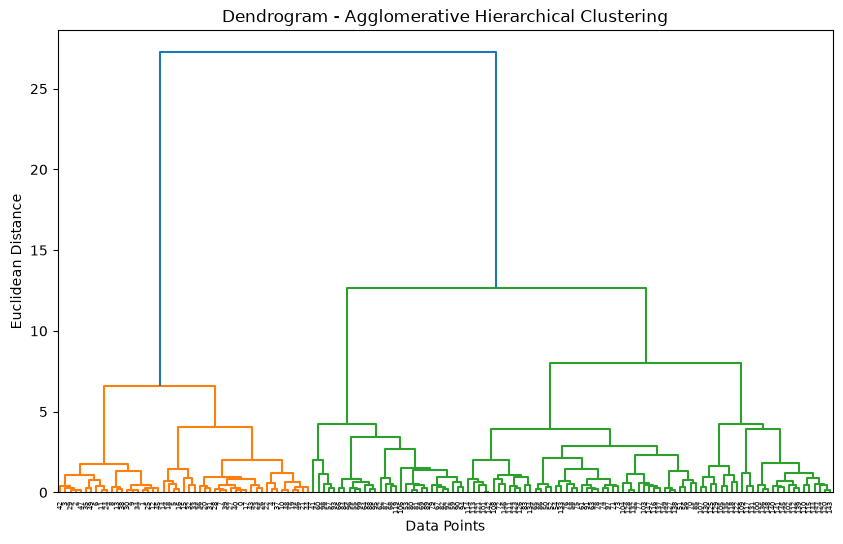


First 10 Clustering Results:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  
5        1  
6        

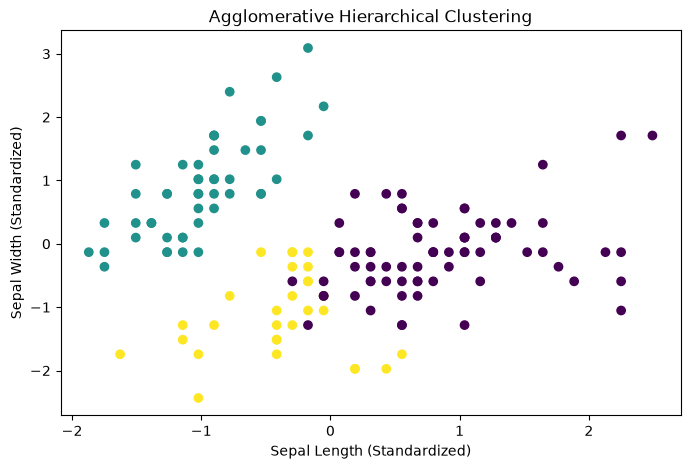

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Step 1: Load the Iris dataset
iris = load_iris()
X = iris.data

# Step 2: Standardize the dataset
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Create the dendrogram
# Ward linkage minimizes the variance within clusters.
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 6))
dendrogram(linked)

plt.title("Dendrogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

# Step 4: Apply Agglomerative Clustering
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Step 5: Fit the model and obtain cluster labels
labels = model.fit_predict(X_scaled)

# Step 6: Display the clustering results
result = pd.DataFrame(X, columns=iris.feature_names)
result["Cluster"] = labels

print("\nFirst 10 Clustering Results:")
print(result.head(10))

print("\nNumber of data points in each cluster:")
print(result["Cluster"].value_counts().sort_index())

# Step 7: Visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis"
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.show()